# Sparse Target Demo

> **Overview.** Our unit search against fully connected networks trained with SGD, Adam and network Autostep, each at
> its best step-size, on a small random sparse target network.

**Problem.** 33 standard normal inputs, two hidden layers of 7 target LTUs, and 7 outputs, each layer's units spread
evenly along the same line. Every target LTU and output reads 10 distinct sources from the layers below it, each drawn
by choosing one of those layers uniformly (the inputs being one) and then a unit in it with probability proportional to
$e^{-d^2 / (2 \cdot 3^2)}$, $d$ being their distance in input spacings, with random $\pm 1$ weights. Each target LTU outputs 1 or 0, with a threshold that
makes it fire 50% of the time. Each output gets $N(0, 0.1^2)$ noise, so the best possible RMSE is 0.1 (dotted line).
Each seed has its own target network.

**Learners.** 14 hidden LTUs per depth, with biases; depth-2 LTUs may read the inputs and depth-1 LTUs, and the outputs
read the inputs and all the LTUs. Every LTU uses the derivative of a sigmoid in the backward pass.
- *Ours* (proposed), the method of `blocked_unit/08_shadow_weights_on_depth_2.ipynb` with every LTU added at the start:
  standardized LTUs with network Autostep (meta step-size 0.02); each LTU has a $\pm 1$ shadow weight, used in the
  backward pass while its real weight is smaller, on an output drawn at random, or, for a depth-1 LTU with equal chance,
  on a depth-2 LTU drawn at random, which then reads it. A new LTU reads 1 to 20 sources drawn in proportion to the
  square of its shadow target's weights on them, with fast learning (signs from those weights, input step-size 0.03); an
  LTU whose shadow target has no such weights yet, as at the start, draws its sources uniformly and keeps random signs.
  Every 100 steps each LTU may grow a connection to the source whose summed gradient stands out from its own noise (4
  times the square root of its summed squared gradients); every 10,000 steps search replaces the 4 LTUs with the
  smallest sum of outgoing weight magnitudes, after a depth-2 LTU that barely reads depth 1 may move to depth 1.
- *Fully connected* (baselines): every LTU reads every input and every LTU of lower depth. With network Autostep,
  standardized LTUs with hidden weights $U(-\alpha_0, \alpha_0)$ and output weights 0; with SGD and Adam, plain LTUs
  and LeCun uniform weights. Every learner updates on each sample, except *batched Adam*, which updates on batches of 16
  new samples, averaging the gradient over the batch.

**Runs.** 500k steps, a step being a sample (batched Adam makes one update per 16), 5 seeds per step-size; the same seed gives every run the same target network and samples.
Step-sizes $2^{-14}$ to $2^{-4}$, every power of 2: SGD's and Adam's step-size, and network Autostep's initial
step-size $\alpha_0$ (for ours, that of the output weights and biases). Curves are the mean over seeds of the RMSE
over the 10 outputs, each sample's error taken before learning from it, averaged over windows of 100 steps; each method's best step-size is the one with the lowest RMSE
over the last 10% of steps.

In [1]:
import os
from functools import partial
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 33
N_PER_DEPTH = 7                      # target LTUs per hidden layer
FAN_IN = 10                          # sources each target LTU and output reads
LOCALITY = 3.0                       # each source is drawn with probability ~ exp(-distance^2 / (2 LOCALITY^2)), in
                                     # input spacings, within its layer
FIRING_RATE = 0.5                    # each target LTU's threshold makes it fire this often
N_OUTPUTS = 7
NOISE_STD = 0.1                      # observation noise on each output: the RMSE floor

# --- Learners ---
N_LTUS = 28                          # hidden LTUs, the first half of depth 1 and the second of depth 2
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the hidden LTUs (network Autostep)
META_STEP_SIZE, TAU = 0.02, 1e4      # network Autostep
STEP_SIZES = 2.0 ** np.arange(-14, -3)   # swept: SGD's and Adam's step-size, network Autostep's initial step-size
BATCH = 16                           # samples per update of batched Adam

# --- Our method ---
MAX_FAN_IN = 20                      # a new LTU reads 1 to MAX_FAN_IN sampled sources
REPLACED = 4                         # LTUs replaced at each search step, those with the smallest sum of |outgoing weights|
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 4.0                         # an LTU connects a source whose gradient sum is this many times the square root
                                     # of its sum of squared gradients
FLAT_SHARE = 0.1                     # a depth-2 LTU with less than this share of its input |weights| on depth-1 LTUs
                                     # acts as a depth-1 LTU
PERIOD = 10_000                      # steps between search steps

# --- Experiment ---
NUM_STEPS = 500_000
WINDOW = 100                         # steps per recorded RMSE, and between growth checks
N_SEEDS = 5

## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (2 * N_PER_DEPTH, N_INPUTS + 2 * N_PER_DEPTH): the target LTUs' weights over [inputs,
                                # target LTUs], +-1 on the sources they read, 0 elsewhere; the first N_PER_DEPTH have depth 1
    threshold: jax.Array        # (2 * N_PER_DEPTH,)
    out: jax.Array              # (N_OUTPUTS, N_INPUTS + 2 * N_PER_DEPTH): the outputs' weights, +-1 on the sources they read


SOURCE_LAYER = np.repeat(np.arange(3), [N_INPUTS, N_PER_DEPTH, N_PER_DEPTH])   # 0: inputs, 1 and 2: target LTU depths


# Each unit's position on a line: the inputs at spacing 1, and each target LTU depth and the outputs spread evenly over
# the same length
POSITION = np.concatenate([np.linspace(0, N_INPUTS - 1, n) for n in (N_INPUTS, N_PER_DEPTH, N_PER_DEPTH, N_OUTPUTS)])


def make_target(key, n_samples=20_000):
    # A target network: each target LTU and output reads FAN_IN distinct sources of lower layers, each drawn by choosing
    # one of those layers uniformly (the inputs being the lowest) and then a unit in it with probability proportional to
    # exp(-distance^2 / (2 LOCALITY^2)) (Gumbel top-k, which samples without replacement in proportion to these
    # probabilities), with random +-1 weights. Each target LTU's threshold makes it fire FIRING_RATE of the time, set
    # depth by depth on a batch of inputs.
    keys = jax.random.split(key, 3)
    below = np.repeat([1, 2, 3], [N_PER_DEPTH, N_PER_DEPTH, N_OUTPUTS])[:, None]   # layers below each unit
    closeness = -(POSITION[N_INPUTS:, None] - POSITION[None, :len(SOURCE_LAYER)]) ** 2 / (2 * LOCALITY ** 2)
    log_p = np.full(closeness.shape, -np.inf)
    for layer in range(3):
        cols = SOURCE_LAYER == layer
        log_p[:, cols] = closeness[:, cols] - np.log(np.exp(closeness[:, cols]).sum(1, keepdims=True))
    log_p = np.where(SOURCE_LAYER < below, log_p, -np.inf)
    top = jax.lax.top_k(log_p + jax.random.gumbel(keys[0], log_p.shape), FAN_IN)[1]
    reads = jnp.zeros(log_p.shape).at[jnp.arange(len(log_p))[:, None], top].set(1.0)
    w = jax.random.rademacher(keys[1], reads.shape, dtype=float) * reads
    x = jax.random.normal(keys[2], (n_samples, N_INPUTS))
    s = jnp.zeros((n_samples, 2 * N_PER_DEPTH))
    threshold = jnp.zeros(2 * N_PER_DEPTH)
    for rows in (slice(0, N_PER_DEPTH), slice(N_PER_DEPTH, 2 * N_PER_DEPTH)):
        z = jnp.concatenate([x, s], 1) @ w[rows].T
        threshold = threshold.at[rows].set(jnp.quantile(z, 1 - FIRING_RATE, axis=0))
        s = s.at[:, rows].set((z > threshold[rows]).astype(float))
    return Target(w[:2 * N_PER_DEPTH], threshold, w[2 * N_PER_DEPTH:])


def sample(target, key):
    # One input and its noisy targets, the target LTUs computed depth by depth.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    s = jnp.zeros(2 * N_PER_DEPTH)
    for rows in (slice(0, N_PER_DEPTH), slice(N_PER_DEPTH, None)):
        s = s.at[rows].set((target.w[rows] @ jnp.concatenate([x, s]) > target.threshold[rows]).astype(float))
    return x, target.out @ jnp.concatenate([x, s]) + NOISE_STD * jax.random.normal(noise_key, (N_OUTPUTS,))

## Learners

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, autostep=True, tau=TAU, version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the hidden LTUs, each shaped (N_LTUS,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each hidden LTU, and of g * h
    error_h_mean: jax.Array


HALF = N_LTUS // 2
DEPTHS = (slice(0, HALF), slice(HALF, N_LTUS))   # the hidden LTUs of depth 1 and of depth 2
# LOWER[u, j]: whether hidden LTU u may read source j of [inputs, hidden LTUs, 1]: every input and the bias, and the
# hidden LTUs of lower depth. A fully connected network reads all of these.
LOWER = jnp.ones((N_LTUS, N_INPUTS + N_LTUS + 1), bool).at[:, N_INPUTS:-1].set(
    (jnp.arange(N_LTUS) >= HALF)[:, None] & (jnp.arange(N_LTUS) < HALF)[None])


class Net(NamedTuple):
    # A network learned with network Autostep. w['hidden'] is the hidden LTUs' weights over [inputs, hidden LTUs, 1 (the
    # bias)], of which they read those in `reads`; w['output'] is the outputs' weights over [inputs, hidden LTUs, 1].
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + N_LTUS + 1), 'output': (N_OUTPUTS, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, N_LTUS): each hidden LTU's shadow weight on an output, and
    shadow_hidden: jax.Array    # (N_LTUS, N_LTUS) on a depth-2 LTU (rows): +-1 on one output or depth-2 LTU, 0 elsewhere
    candidates: jax.Array       # (2, N_LTUS, N_INPUTS + N_LTUS): sums of dL/dz * source and of its square since each
                                # LTU's last new connection


def init_net(key, step_size, connected):
    # Fully connected if connected: hidden weights U(-step_size, step_size) on every source but the bias; otherwise no
    # connections yet. Output weights and biases 0, every Autostep step-size at step_size, no shadow weights.
    reads = LOWER if connected else jnp.zeros_like(LOWER).at[:, -1].set(True)
    hidden = jax.random.uniform(key, LOWER.shape, minval=-step_size, maxval=step_size) * reads
    w = {'hidden': hidden.at[:, -1].set(0.0), 'output': jnp.zeros((N_OUTPUTS, N_INPUTS + N_LTUS + 1))}
    opt = OPTIMIZER.init(w)
    opt = opt._replace(init_beta=jnp.log(step_size), beta=jax.tree.map(lambda a: jnp.full_like(a, jnp.log(step_size)), w))
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    return Net(w, reads, opt, stats, jnp.zeros((N_OUTPUTS, N_LTUS)), jnp.zeros((N_LTUS, N_LTUS)),
               jnp.zeros((2, N_LTUS, N_INPUTS + N_LTUS)))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, the hidden LTUs computed
    # depth by depth, each shadow weight standing in for its LTU's weight to that output or depth-2 LTU in the backward
    # pass while the real one is smaller in magnitude, the other weights used as they are. Returns the new network and
    # the squared error on this sample averaged over the outputs, before learning from it, and adds dL/dz * source and
    # its square to each hidden LTU's gradient sums. `probe` is zero; its gradients are the error arriving at each
    # hidden LTU and dL/dz.

    def loss_fn(w, probe):
        w = {**w, 'hidden': w['hidden'] * net.reads}

        def back(shadow, real):
            # The weights used in the backward pass: each shadow weight while the real one is smaller in magnitude.
            return jax.lax.stop_gradient(jnp.where((shadow != 0) & (jnp.abs(real) < 1.0), shadow, real))

        hidden_back = back(net.shadow_hidden, w['hidden'][:, N_INPUTS:-1])
        a, means, hs = jnp.zeros(N_LTUS), [], []
        for rows in DEPTHS:
            through_back = hidden_back[rows] @ a
            z = (w['hidden'][rows] @ jax.lax.stop_gradient(jnp.concatenate([x, a, jnp.ones(1)])) + through_back
                 - jax.lax.stop_gradient(through_back))
            b = ltu(z + probe[1][rows])
            mean = net.stats.hidden_mean[rows] + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean[rows])
            h = standardize(b, mean, net.stats.error_mean[rows], net.stats.error_h_mean[rows])
            a = a.at[rows].set(h + probe[0][rows])
            means.append(mean)
            hs.append(jax.lax.stop_gradient(h))
        source = jax.lax.stop_gradient(jnp.concatenate([x, a, jnp.ones(1)]))
        through_back = back(net.shadow, w['output'][:, N_INPUTS:-1]) @ a
        prediction = w['output'] @ source + through_back - jax.lax.stop_gradient(through_back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (source, jnp.concatenate(hs), jnp.concatenate(means))

    (loss, (source, h, mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {**grads, 'hidden': grads['hidden'] * net.reads}
    error, dz = error
    sources = {'hidden': source[None] * net.reads, 'output': source[None]}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    grad = dz[:, None] * source[:-1]
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + jnp.stack([grad, grad ** 2])), 2 * loss / N_OUTPUTS


def init_plain(key):
    # A fully connected network for SGD and Adam: LeCun uniform weights over each unit's fan-in, biases 0.
    hidden_key, output_key = jax.random.split(key)
    fan_in = LOWER[:, :-1].sum(1, keepdims=True)
    hidden = jax.random.uniform(hidden_key, LOWER.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / fan_in) * LOWER
    output = jax.random.uniform(output_key, (N_OUTPUTS, N_INPUTS + N_LTUS + 1), minval=-1.0, maxval=1.0)
    return {'hidden': hidden.at[:, -1].set(0.0), 'output': (output * jnp.sqrt(1.0 / (N_INPUTS + N_LTUS))).at[:, -1].set(0.0)}


def learn_plain(state, x, y, optimizer):
    # One update of a fully connected network of plain LTUs (bits) on a batch of samples, x (batch, N_INPUTS) and y
    # (batch, N_OUTPUTS), on half the squared error summed over the outputs and averaged over the batch. Returns the new
    # (weights, optimizer state) and each sample's squared error averaged over the outputs, before learning from them.
    def loss_fn(w):
        ones = jnp.ones((len(x), 1))
        a = jnp.zeros((len(x), N_LTUS))
        for rows in DEPTHS:
            a = a.at[:, rows].set(ltu(jnp.concatenate([x, a, ones], 1) @ (w['hidden'][rows] * LOWER[rows]).T))
        errors = jnp.sum((jnp.concatenate([x, a, ones], 1) @ w['output'].T - y) ** 2, 1)
        return 0.5 * errors.mean(), errors

    w, opt = state
    (_, errors), grads = jax.value_and_grad(loss_fn, has_aux=True)(w)
    updates, opt = optimizer.update(grads, opt, w)
    return (optax.apply_updates(w, updates), opt), errors / N_OUTPUTS

## Our Method

In [5]:
def shadow_target_weights(net):
    # Shaped like w['hidden']: each hidden LTU's shadow weight times its shadow target's weights on the sources it may
    # read, 0 elsewhere and on the bias.
    targets = net.shadow.T @ net.w['output'] + net.shadow_hidden.T @ (net.w['hidden'] * net.reads)
    return targets.at[:, -1].set(0.0) * LOWER


def usefulness(net):
    # Each hidden LTU's sum of |outgoing weights|, to the outputs and to depth-2 LTUs.
    return (jnp.abs(net.w['output'][:, N_INPUTS:-1]).sum(0)
            + jnp.abs(net.w['hidden'][:, N_INPUTS:-1] * net.reads[:, N_INPUTS:-1]).sum(0))


def redraw(net, key, replaced):
    # The `replaced` hidden LTUs' new shadow weights, +1 or -1 by slot: a depth-2 LTU's on an output drawn at random, and
    # a depth-1 LTU's, with equal chance, on an output or a depth-2 LTU drawn at random.
    layer_key, output_key, unit_key = jax.random.split(key, 3)
    slot = jnp.arange(N_LTUS)
    on_hidden = (slot < HALF) & (jax.random.uniform(layer_key, (N_LTUS,)) < 0.5)
    unit = jax.random.randint(unit_key, (N_LTUS,), HALF, N_LTUS)
    output = jax.random.randint(output_key, (N_LTUS,), 0, N_OUTPUTS)
    sign = jnp.where(slot % 2 == 0, 1.0, -1.0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == output) * jnp.where(on_hidden, 0.0, sign)
    shadow_hidden = (slot[:, None] == unit) * jnp.where(on_hidden, sign, 0.0)
    return net._replace(shadow=jnp.where(replaced, shadow, net.shadow),
                        shadow_hidden=jnp.where(replaced, shadow_hidden, net.shadow_hidden))


def rewire(net, key, replaced, rows):
    # The `rows` hidden LTUs (a mask over slots, among the `replaced` LTUs) each read 1 to MAX_FAN_IN sources (uniform,
    # but no more than their shadow target has nonzero weights on) and the bias, the sources, inputs and lower-depth LTUs
    # alike, drawn without replacement with probability proportional to the square of their shadow target's weight on
    # them (Gumbel top-k), or uniformly among the sources they may read if their shadow target has no such weights yet,
    # with fresh LeCun uniform weights over their fan-in, output weights at 0, and fresh statistics, Autostep state and
    # gradient sums; the other LTUs' connections from the replaced LTUs are cut. Then every LTU reads the LTUs with
    # shadow weights on it, connections it lacks starting at weight 0 with step-size FAST_STEP_SIZE.
    fan_key, draw_key, w_key = jax.random.split(key, 3)
    cut = jnp.zeros_like(net.reads).at[:, N_INPUTS:-1].set(replaced[None])   # connections from the replaced LTUs
    weights = jnp.where(cut, 0.0, shadow_target_weights(net))[:, :-1]
    weights = jnp.where(jnp.any(weights != 0, 1, keepdims=True), weights, (LOWER & ~cut)[:, :-1])
    fan_in = jnp.minimum(jax.random.randint(fan_key, (N_LTUS, 1), 1, MAX_FAN_IN + 1),
                         (weights != 0).sum(1, keepdims=True))
    scores = jnp.log(weights ** 2) + jax.random.gumbel(draw_key, weights.shape)
    reads = jnp.append(jnp.argsort(jnp.argsort(-scores)) < fan_in, jnp.ones((N_LTUS, 1), bool), axis=1)
    hidden = (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / jnp.maximum(fan_in, 1))
              * reads)
    changed = rows[:, None] | cut
    reads = jnp.where(changed, reads, net.reads)
    served = jnp.zeros_like(reads).at[:, N_INPUTS:-1].set(net.shadow_hidden != 0) & ~reads
    where = {'hidden': changed,
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), rows, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    w = reset(net.w, {'hidden': hidden.at[:, -1].set(0.0), 'output': jnp.zeros_like(net.w['output'])})
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    beta = reset(net.opt.beta, jax.tree.map(lambda a: a + net.opt.init_beta, zeros))
    beta = {**beta, 'hidden': jnp.where(served, jnp.log(FAST_STEP_SIZE), beta['hidden'])}
    opt = net.opt._replace(beta=beta, h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(rows, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=w, reads=reads | served, opt=opt, stats=stats,
                        candidates=jnp.where(changed[:, :-1], 0.0, net.candidates))


def speed_up(net, rows):
    # The `rows` hidden LTUs' weights keep their magnitudes but take the signs of their shadow weight times their shadow
    # target's weights on those sources (where that weight is not 0), and the step-sizes of all their weights but the
    # bias's start at FAST_STEP_SIZE.
    sources = net.reads.at[:, -1].set(False) & rows[:, None]
    sign = jnp.sign(shadow_target_weights(net))
    hidden = jnp.where(sources & (sign != 0), jnp.abs(net.w['hidden']) * sign, net.w['hidden'])
    beta = jnp.where(sources, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': hidden}, opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def start(net, key, replaced):
    # The replaced LTUs given new shadow weights, rewired and sped up, those of depth 2 first, so that depth-1 LTUs with
    # shadow weights on depth-2 LTUs draw on their new weights.
    keys = jax.random.split(key, 3)
    net = redraw(net, keys[0], replaced)
    for depth, depth_key in zip(DEPTHS[::-1], keys[1:]):
        rows = replaced & jnp.zeros(N_LTUS, bool).at[depth].set(True)
        net = speed_up(rewire(net, depth_key, replaced, rows), rows)
    return net


def grow(net):
    # Each hidden LTU with a source it may read but does not whose gradient sum is more than GROW_Z times the square
    # root of its sum of squared gradients connects the one where this is largest, at weight 0 with step-size
    # FAST_STEP_SIZE, and restarts its sums.
    unread = LOWER[:, :-1] & ~net.reads[:, :-1]
    sums = jnp.where(unread, jnp.abs(net.candidates[0]) / jnp.sqrt(net.candidates[1] + 1e-12), 0.0)
    best = jnp.argmax(sums, 1)
    grows = jnp.max(sums, 1) > GROW_Z
    new = (jnp.arange(N_INPUTS + N_LTUS + 1) == best[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def swap(net, i, j):
    # Slots i and j exchange their LTUs, but the shadow weights on depth-2 slot j stay on it; the LTU arriving at
    # depth-1 slot i loses its connections from hidden LTUs.
    perm = jnp.arange(N_LTUS).at[i].set(j).at[j].set(i)
    cols = jnp.concatenate([jnp.arange(N_INPUTS), N_INPUTS + perm, jnp.array([N_INPUTS + N_LTUS])])
    tree = lambda t: {'hidden': t['hidden'][perm][:, cols], 'output': t['output'][:, cols]}
    net = net._replace(w=tree(net.w), reads=net.reads[perm][:, cols],
                       opt=net.opt._replace(beta=tree(net.opt.beta), h=tree(net.opt.h), v=tree(net.opt.v)),
                       stats=Stats(*(a[perm] for a in net.stats)), shadow=net.shadow[:, perm],
                       shadow_hidden=net.shadow_hidden[:, perm], candidates=net.candidates[:, perm][:, :, cols[:-1]])
    cut = jnp.zeros_like(net.reads).at[i, N_INPUTS:-1].set(True)
    zero = lambda t: {**t, 'hidden': jnp.where(cut, 0.0, t['hidden'])}
    beta = jnp.where(cut, net.opt.init_beta, net.opt.beta['hidden'])
    return net._replace(w=zero(net.w), reads=net.reads & ~cut,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}, h=zero(net.opt.h), v=zero(net.opt.v)))


def search(net, key):
    # The strongest depth-2 LTU acting as a depth-1 LTU (if any) swaps slots with the weakest depth-1 LTU, if weaker;
    # then the REPLACED LTUs with the smallest sum of |outgoing weights| are given new shadow weights and rewired.
    outgoing = usefulness(net)
    links = jnp.abs(net.w['hidden'][:, :-1]) * net.reads[:, :-1]
    flat = (jnp.arange(N_LTUS) >= HALF) & (links[:, N_INPUTS:].sum(1) < FLAT_SHARE * links.sum(1))
    mover = jnp.argmax(jnp.where(flat, outgoing, -jnp.inf))
    weak = jnp.argmin(jnp.where(jnp.arange(N_LTUS) < HALF, outgoing, jnp.inf))
    moved = flat.any() & (outgoing[mover] > outgoing[weak])
    net = jax.tree.map(lambda a, b: jnp.where(moved, a, b), swap(net, weak, mover), net)
    outgoing = jnp.where(moved, outgoing.at[weak].set(outgoing[mover]).at[mover].set(-1.0), outgoing)
    weakest = jnp.argsort(outgoing)[:REPLACED]
    return start(net, key, jnp.zeros(N_LTUS, bool).at[weakest].set(True))

## Training

In [6]:
METHODS = ('ours', 'network Autostep', 'SGD', 'Adam', 'batched Adam')


def train(init_key, key, target, step_size, method):
    # NUM_STEPS samples from `target` with `method` at `step_size` (network Autostep's initial step-size), one update
    # per sample, or per BATCH samples for batched Adam. Ours starts with every LTU added (new shadow weights, rewired,
    # sped up), grows every WINDOW steps and searches every PERIOD steps. Returns each window's mean squared error, each
    # sample's taken before learning from it.
    n = NUM_STEPS // WINDOW
    index, keys = jnp.arange(n), jax.random.split(key, n)
    if method in ('SGD', 'Adam', 'batched Adam'):
        optimizer = optax.sgd(step_size) if method == 'SGD' else optax.adam(step_size)
        w = init_plain(init_key)
        batch = BATCH if method == 'batched Adam' else 1
        batches = jax.vmap(lambda k: jax.random.split(k, WINDOW))(keys).reshape(NUM_STEPS // batch, batch, -1)
        step = lambda state, k: learn_plain(state, *jax.vmap(sample, (None, 0))(target, k), optimizer)
        return jax.lax.scan(step, (w, optimizer.init(w)), batches)[1].reshape(n, WINDOW).mean(1)
    if method == 'ours':
        net = start(init_net(init_key, step_size, False), jax.random.fold_in(init_key, 1), jnp.ones(N_LTUS, bool))
    else:
        net = init_net(init_key, step_size, True)

    def window(net, inputs):
        index, key = inputs
        net, mse = jax.lax.scan(lambda s, k: learn(s, *sample(target, k)), net, jax.random.split(key, WINDOW))
        if method == 'ours':
            net = grow(net)
            due = (index + 1) * WINDOW % PERIOD == 0
            net = jax.tree.map(lambda a, b: jnp.where(due, a, b), search(net, jax.random.fold_in(key, 1)), net)
        return net, mse.mean()

    return jax.lax.scan(window, net, (index, keys))[1]


def run(method):
    # `method` at each of STEP_SIZES on N_SEEDS seeds, vmapped together; seed s gives every run the same target network
    # and samples. Returns the RMSE of each window, shaped (step size, seed, window).
    step_size, seed = (jnp.array(v) for v in zip(*[(a, s) for a in STEP_SIZES for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(make_target)(keys(2))
    mse = jax.jit(jax.vmap(partial(train, method=method)))(keys(0), keys(1), targets, step_size)
    return np.sqrt(np.asarray(mse)).reshape(len(STEP_SIZES), N_SEEDS, -1)

## Runs

In [7]:
started = perf_counter()
rmse = {method: run(method) for method in METHODS}
print(f'{len(METHODS) * len(STEP_SIZES) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

275 runs in 110s


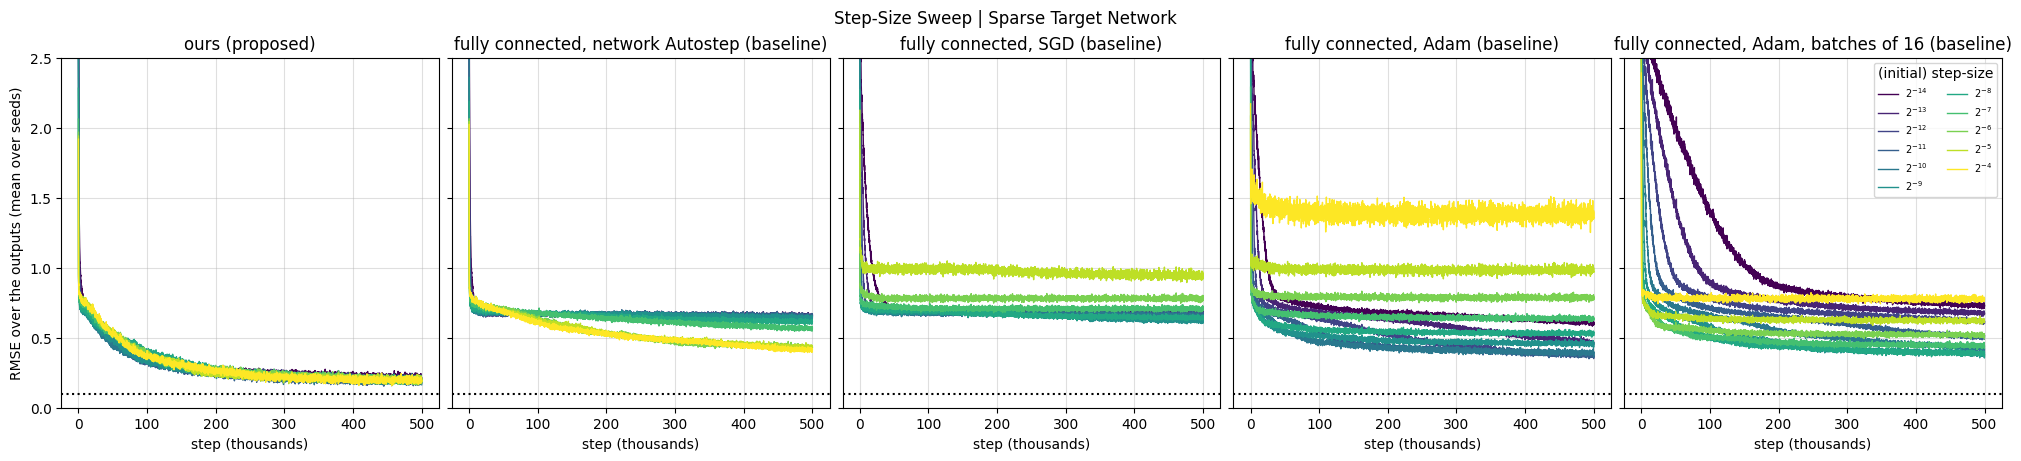

In [8]:
STEPS = (np.arange(NUM_STEPS // WINDOW) + 1) * WINDOW
LABELS = {'ours': 'ours (proposed)', 'network Autostep': 'fully connected, network Autostep (baseline)',
          'SGD': 'fully connected, SGD (baseline)', 'Adam': 'fully connected, Adam (baseline)',
          'batched Adam': f'fully connected, Adam, batches of {BATCH} (baseline)'}
COLORS = {'ours': 'tab:blue', 'network Autostep': 'tab:red', 'SGD': 'tab:orange', 'Adam': 'tab:brown',
          'batched Adam': 'tab:purple'}
power = lambda step_size: f'$2^{{{int(np.log2(step_size))}}}$'

fig, axes = plt.subplots(1, len(METHODS), figsize=(20, 4.5), sharey=True, layout='constrained')
for ax, method in zip(axes, METHODS):
    for step_size, curves, color in zip(STEP_SIZES, rmse[method], plt.cm.viridis(np.linspace(0, 1, len(STEP_SIZES)))):
        ax.plot(STEPS / 1000, curves.mean(0), color=color, lw=1, label=power(step_size))
    ax.axhline(NOISE_STD, color='black', ls=':')
    ax.set(title=LABELS[method], xlabel='step (thousands)', ylim=(0, 2.5))
    ax.grid(alpha=0.4)
axes[0].set_ylabel('RMSE over the outputs (mean over seeds)')
axes[-1].legend(title='(initial) step-size', fontsize=7, ncols=2)
fig.suptitle('Step-Size Sweep | Sparse Target Network')
plt.show()

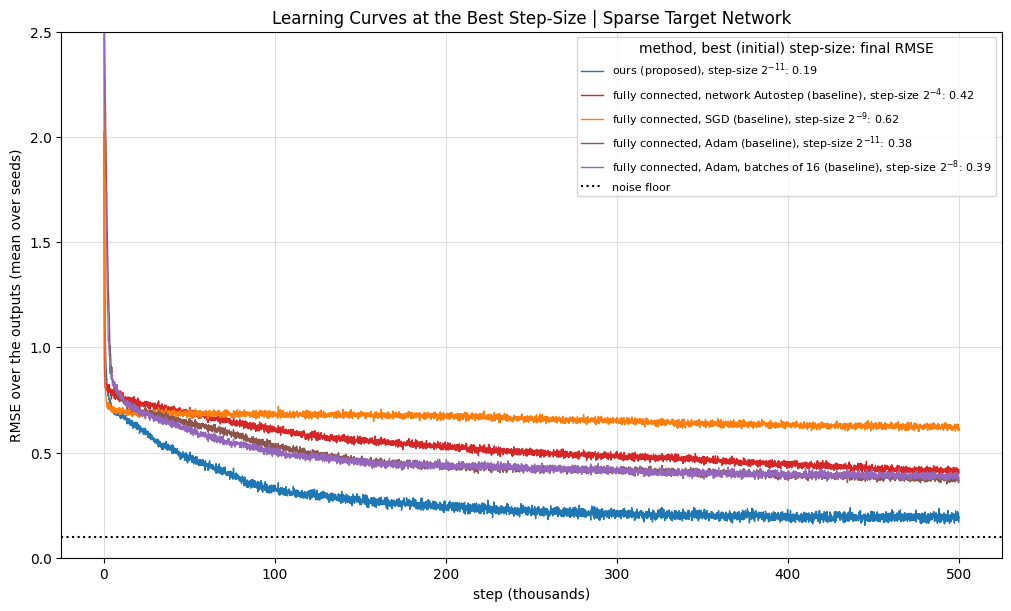

In [9]:
fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
for method in METHODS:
    final = rmse[method][..., -rmse[method].shape[-1] // 10:].mean((1, 2))   # each step-size's RMSE over the last 10%
    best = np.nanargmin(final)
    ax.plot(STEPS / 1000, rmse[method][best].mean(0), color=COLORS[method], lw=1,
            label=f'{LABELS[method]}, step-size {power(STEP_SIZES[best])}: {final[best]:.2f}')
ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
ax.set(xlabel='step (thousands)', ylabel='RMSE over the outputs (mean over seeds)', ylim=(0, 2.5),
       title='Learning Curves at the Best Step-Size | Sparse Target Network')
ax.grid(alpha=0.4)
ax.legend(fontsize=8, title='method, best (initial) step-size: final RMSE')
plt.show()

## Results

5 seeds per step-size, 500k steps. The notebook takes about 2 minutes.

- **Ours does best**: RMSE over the last 10% of steps 0.19 (step-size $2^{-11}$, and nearly the same at every
  step-size), against 0.38 for Adam ($2^{-11}$), 0.39 for Adam with batches of 16 ($2^{-8}$), 0.42 for network Autostep
  (initial step-size $2^{-4}$, the largest tried) and 0.62 for SGD ($2^{-9}$).